**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_014_공식형_분류_자동차보험청구분석

### **자동차보험 청구 분석 — <span style="color:darkgreen">부정청구 여부</span> 예측 모델 개발**
---

- 도메인 : 자동차보험 청구 분석
- 목  표 : 보험 청구의 부정 의심 여부를 예측하는 인공지능모델 개발
- 보상팀은 청구 정보를 분석해 의심 건을 우선 조사하려 한다.
- 부정 청구로 인한 보험금 누수가 늘어 다정다이렉트의 손해율이 악화되고 있다.
- 청구 건 730건 안팎의 이력 데이터를 활용할 수 있다.
- 모델이 부정청구 여부를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 다정다이렉트의 데이터로 보험 청구의 부정 의심 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, pivot_table, iloc, quantile, copy, median, drop, get_dummies, info, DataFrame, reset_index, columns, sort_values, shape) · NumPy(where, log1p) · matplotlib(import matplotlib.pyplot as plt, plot, title, xlabel, ylabel, legend, show) · scikit-learn(SimpleImputer, fit_transform, train_test_split, MinMaxScaler, transform, RandomForestClassifier, fit, DecisionTreeClassifier, feature_importances_, predict, f1_score, LabelEncoder) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, ReduceLROnPlateau, Dense, Activation, BatchNormalization, Dropout, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 3.0 / 5)
- 예상 소요 시간 : 약 130분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 자동차보험 청구 분석 (금융·보험)

**[ 데이터 컬럼 설명 (데이터 파일명: data.tsv) ]**

- CASE_ID               : 사례 식별번호
- CLAIM_AMOUNT          : 청구 금액(만원)
- POLICY_AGE            : 보험 가입 기간(개월)
- N_CLAIMS_PREV         : 과거 청구 횟수
- VEHICLE_VALUE         : 차량 가액(만원)
- ANNUAL_KM             : 연간 주행거리(천km)
- REPAIR_EST            : 정비 견적(만원)
- REPORT_DELAY_D        : 사고 접수 지연(일)
- WITNESS_CNT           : 목격자 수
- PREMIUM_KRW           : 연 보험료(만원)
- COVERAGE              : 담보 유형
- VEHICLE_TYPE          : 차종
- REGION                : 사고 지역
- FRAUD_FLAG            : 부정청구 여부 (Normal, Fraud)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [2]:
import numpy as np
import seaborn as sns

### **1. 그래프 시각화을 위해 matplotlib 라이브러리를 사용하려고 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: matplotlib(import matplotlib.pyplot as plt) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `matplotlib.pyplot`
- 별칭(alias) : `plt`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [3]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import matplotlib.pyplot as plt


In [ ]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답01 = 'matplotlib.pyplot'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 17글자이고 첫 글자는 `m` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotli________ as plt

정답01 = 'matplotli________'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 제시된 가이드에 맞춰 파일을 읽어 df_raw 에 저장하고 처음 6개 행을 확인하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_csv, head) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 저장할 변수 이름 : df_raw
    - 데이터 파일명 : data.tsv
    - 경로 없이 파일 이름만으로 읽을 수 있습니다
    - 컬럼 구분자는 탭(\t) 입니다
- **[결과 변수]** 결과는 반드시 `df_raw` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_raw.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 5점

---

In [5]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd
df_raw = pd.read_csv('aa23-m4-data.tsv', sep='\t')
df_raw.head(6)
print(df_raw.shape)

(727, 14)


In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(727, 14)

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_raw` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import pandas as pd

df_raw = pd.read_csv('./data.tsv', sep='\t')
df_raw.head(6)

# [df_raw] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_raw.shape)
```

</details>

### **3. 담보 유형(COVERAGE)와(과) 차종(VEHICLE_TYPE) 두 기준으로 사고 접수 지연(일)(REPORT_DELAY_D)의 평균을 한눈에 비교하고자 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(pivot_table) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 로 `pivot_table` 을 만들어 `pt` 에 담으세요 (행: COVERAGE, 열: VEHICLE_TYPE, 값: REPORT_DELAY_D, 집계 함수(aggfunc): 'mean')
- 아래 코드 셀의 빈칸 `< blank03_1 >`, `< blank03_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답03_1`, `정답03_2` 변수에 각각 저장하세요
    - 예시) 정답03_0 = 'data'
- 배점 : 5점

---

In [6]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

pt = df_raw.pivot_table(index='COVERAGE', columns='VEHICLE_TYPE', values='REPORT_DELAY_D', aggfunc='mean')


In [ ]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답03_1 = 'pivot_table'
정답03_2 = 'values'


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

행·열로 쓸 범주 컬럼, 값 컬럼, 집계 함수를 pivot_table 인자로 지정하세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `pivot_table`. 정답은 6글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
pt = df_raw.pivot______(index='COVERAGE', columns='VEHICLE_TYPE', val___='REPORT_DELAY_D', aggfunc='mean')

정답03_1 = 'pivot______'   # 빈칸 1에 넣은 단어
정답03_2 = 'val___'   # 빈칸 2에 넣은 단어
```

</details>

### **4. 컬럼 이름이 아니라 **위치 번호**로 데이터를 선택하고자 합니다. iloc 를 활용하십시오.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(iloc) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 에서 행 위치 23, 열 위치 8 (둘 다 0부터 시작)의 값을 `iloc` 로 선택해 `cell` 에 담으세요
    - 이어서 첫 5개 행, 첫 3개 열만 `iloc` 슬라이싱으로 선택해 `sub` 에 보관하세요
- **[정답04]** `cell` 의 값을 소수 둘째 자리까지 작성하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [7]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

cell = df_raw.iloc[23, 8]
sub = df_raw.iloc[:5, :3]

round(cell, 2)


np.float64(1.0)

In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답04 = 1.0


<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

위치 기반 선택에는 iloc 를 쓰고, 슬라이스는 `시작:끝` 형태입니다. cell 값을 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `iloc`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
cell = df_raw.iloc[23, 8]
sub = df_raw.iloc[:5, :3]

# [정답04] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(cell, __)
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 목격자 수(WITNESS_CNT) 컬럼의 이상치는 삭제하지 않고 중앙값으로 바꿔 데이터 손실을 줄이려 합니다.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, copy, median, drop) · NumPy(where) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_raw
    - IQR 기준(K=1.5)으로 lower_fence, upper_fence 를 계산하세요
    - 식별자 컬럼 CASE_ID 를 삭제한 사본을 df_clean 에 담으세요
    - df_clean 의 WITNESS_CNT 중앙값을 `med` 에 저장하고, 두 fence 를 벗어난 값은 `np.where` 로 `med` 로 바꾸세요(행은 삭제하지 않음)
- **[결과 변수]** 결과는 반드시 `df_clean` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_clean.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [8]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

q1 = df_raw['WITNESS_CNT'].quantile(0.25)
q3 = df_raw['WITNESS_CNT'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_clean = df_raw.drop(columns=['CASE_ID']).copy()
med = df_clean['WITNESS_CNT'].median()
df_clean['WITNESS_CNT'] = np.where((df_clean['WITNESS_CNT'] < lower_fence) | (df_clean['WITNESS_CNT'] > upper_fence), med, df_clean['WITNESS_CNT'])

print(df_clean.shape)

(727, 13)


In [ ]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(727, 13)

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

fence 를 벗어나는 값을 조건으로 만들고, 그 값만 중앙값으로 바꿉니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `median`, `np.where`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_clean` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import numpy as np

q1 = df_raw['WITNESS_CNT'].quantile(0.25)
q3 = df_raw['WITNESS_CNT'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

df_clean = df_raw.drop(columns=['CASE_ID']).copy()
med = df_clean['WITNESS_CNT'].median()
df_clean['WITNESS_CNT'] = np.where((df_clean['WITNESS_CNT'] < lower_fence) | (df_clean['WITNESS_CNT'] > upper_fence), med, df_clean['WITNESS_CNT'])

# [df_clean] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_clean.shape)
```

</details>

### **6. 결측치를 sklearn 의 SimpleImputer 로 처리하려 합니다. 아래 가이드에 따라 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(copy) · scikit-learn(SimpleImputer, fit_transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_clean (사본을 df_filled 에 저장해 처리)
    - 수치형 컬럼(N_CLAIMS_PREV, ANNUAL_KM): strategy='median' (중앙값)
    - 처리 후 결측치가 남아 있지 않아야 합니다
- **[결과 변수]** 결과는 반드시 `df_filled` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_filled.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [9]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.impute import SimpleImputer

df_filled = df_clean.copy()
imp_num = SimpleImputer(strategy='median')
df_filled[['N_CLAIMS_PREV', 'ANNUAL_KM']] = imp_num.fit_transform(df_filled[['N_CLAIMS_PREV', 'ANNUAL_KM']])

print(df_filled.shape)

(727, 13)


In [ ]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(727, 13)

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치 대체 전용 변환기를 만들어 해당 컬럼에 fit_transform 합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `SimpleImputer`, `fit_transform`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_filled` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.impute import SimpleImputer

df_filled = df_clean.copy()
imp_num = SimpleImputer(strategy='median')
df_filled[['N_CLAIMS_PREV', 'ANNUAL_KM']] = imp_num.fit_transform(df_filled[['N_CLAIMS_PREV', 'ANNUAL_KM']])

# [df_filled] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_filled.shape)
```

</details>

### **7. 정비 견적(만원)(REPAIR_EST)의 분포가 한쪽으로 치우쳐 있을 수 있어, 로그 변환으로 치우침을 줄이려 합니다.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) · NumPy(log1p) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `df_filled`
- 대상 데이터프레임 : df_filled
- `np.log1p` 로 REPAIR_EST 을 변환한 값을 새 컬럼 `REPAIR_EST_log` 으로 추가하세요 (log1p(x) = log(1 + x))
- **[정답07]** 변환한 `REPAIR_EST_log` 의 **왜도**(`skew()`)를 소수점 둘째 자리까지 작성하세요
- 문자열/범주형 컬럼 COVERAGE, VEHICLE_TYPE, REGION 을(를) get_dummies(drop_first=True)로 인코딩해 df_final 에 저장하세요
- 답안 : **[정답07]** 의 값만 코드 셀 맨 아래에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [10]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_filled['REPAIR_EST_log'] = np.log1p(df_filled['REPAIR_EST'])

df_final = pd.get_dummies(data=df_filled, columns=['COVERAGE', 'VEHICLE_TYPE', 'REGION'], drop_first=True)
df_final.info()

round(df_filled['REPAIR_EST'].skew(), 2)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 727 entries, 0 to 726
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CLAIM_AMOUNT     727 non-null    float64
 1   POLICY_AGE       727 non-null    float64
 2   N_CLAIMS_PREV    727 non-null    float64
 3   VEHICLE_VALUE    727 non-null    float64
 4   ANNUAL_KM        727 non-null    float64
 5   REPAIR_EST       727 non-null    float64
 6   REPORT_DELAY_D   727 non-null    float64
 7   WITNESS_CNT      727 non-null    float64
 8   PREMIUM_KRW      727 non-null    float64
 9   FRAUD_FLAG       727 non-null    object 
 10  REPAIR_EST_log   727 non-null    float64
 11  COVERAGE_대인      727 non-null    bool   
 12  COVERAGE_자손      727 non-null    bool   
 13  COVERAGE_자차      727 non-null    bool   
 14  VEHICLE_TYPE_경차  727 non-null    bool   
 15  VEHICLE_TYPE_승용  727 non-null    bool   
 16  VEHICLE_TYPE_화물  727 non-null    bool   
 17  REGION_서울       

np.float64(3.59)

In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답07 = 3.59

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

값이 0 이어도 계산되는 로그 변환 함수를 컬럼에 적용해 새 컬럼에 저장하세요. 남은 문자열 컬럼을 모두 0/1 컬럼으로 바꿉니다. 새 컬럼의 skew() 를 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `np.log1p`, `pd.get_dummies`, `skew`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

df_filled['REPAIR_EST_log'] = np.log1p(df_filled['REPAIR_EST'])

df_final = pd.get_dummies(data=df_filled, columns=['COVERAGE', 'VEHICLE_TYPE', 'REGION'], drop_first=True)
df_final.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(df_filled['____'].skew(), __)
```

</details>

### **8. 모델 성능을 확인할 검증 데이터를 따로 떼어 두려고 합니다. 아래 가이드에 따라 분리하십시오.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 대상 데이터프레임 : df_final
- 부정청구 여부(FRAUD_FLAG) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 반환값을 담을 변수 : X_train(훈련 피처), X_valid(검증 피처), y_train(훈련 레이블), y_valid(검증 레이블)
- 데이터를 훈련 65 : 검증 35 로 분할합니다 (test_size=0.35)
- 클래스 비율을 유지하는 층화 추출(stratify=y)을 적용하세요 / scikit-learn 의 train_test_split 함수를 활용하세요
- random_state 는 7 로 고정하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [11]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.model_selection import train_test_split

X = df_final.drop('FRAUD_FLAG', axis=1)
y = df_final['FRAUD_FLAG']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.35, random_state=7, stratify=y)

print(len(X_valid))

255


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
255

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('FRAUD_FLAG', axis=1)
y = df_final['FRAUD_FLAG']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.35, random_state=7, stratify=y)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 가이드에 따라 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 sc 변수에 지정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 저장하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[정답09]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 소수 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 코드 셀 맨 아래에 `정답09 = 값` 형태로 입력하세요
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [12]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

round(np.max(X_valid), 2)


np.float64(1.73)

In [ ]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답09 = '1.73'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 부정청구 여부(FRAUD_FLAG)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. RandomForest와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(RandomForestClassifier, fit, DecisionTreeClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=200, max_depth=4
    - 난수 시드(random_state) : 1
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=3, min_samples_leaf=5
    - 난수 시드(random_state) : 1
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `rf`(RandomForest) 의 **훈련 데이터** 점수 `rf.score(X_train, y_train)` (정확도(accuracy))를 소수점 셋째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [13]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=1)
rf.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=1)
dt.fit(X_train, y_train)

round(rf.score(X_train, y_train), 3)


0.854

In [ ]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답10 = 0.854

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `RandomForestClassifier`, `fit`, `DecisionTreeClassifier`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=1)
rf.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=1)
dt.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(rf.score(X_train, y_train), __)
```

</details>

### **11. DecisionTree 모델의 변수중요도 상위 3개 변수가 전체 설명력의 얼마를 차지하는지 확인하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, reset_index, head, columns) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 8번 `X` · 10번 `dt`
- 학습된 DecisionTree 모델 `dt` 의 변수중요도를 변수명과 매핑한 DataFrame `fi` 로 만들고 내림차순 정렬하세요
    - 상위 3개 행을 `top_n` 에 저장하세요
- **[정답11]** 상위 3개 변수 중요도의 **합계**를 소수점 둘째 자리까지 입력하세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [14]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(3)

round(top_n['importance'].sum(), 2)


np.float64(0.98)

In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답11 = 0.98

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 DataFrame 을 만들어 정렬한 뒤 위에서 N개를 선택합니다. top_n 의 importance 컬럼을 합하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `feature_importances_`, `sort_values`, `head`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

fi = pd.DataFrame({'feature': X.columns, 'importance': dt.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(3)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(top_n['____'].sum(), __)
```

</details>

### **12. 앞서 학습시킨 RandomForest와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, f1_score) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `rf`
- 아래 가이드에 따라 각 모델의 F1-score(macro) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 정정하세요
    - 앞서 학습시킨 rf 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 F1-score(macro) 값을 각각 rf_score, dt_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 F1-score(macro) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (RandomForest / DecisionTree 중 하나)
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [15]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import f1_score

y_pred_rf = rf.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

rf_score = f1_score(y_valid, y_pred_rf, average='macro')
dt_score = f1_score(y_valid, y_pred_dt, average='macro')
print(rf_score, dt_score)


0.7311915148959633 0.7486629287918694


In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답12 = 'DecisionTree'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. F1-score(macro) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import f1_score

y_pred_rf = rf.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

rf_score = f1_score(y_valid, y_pred_rf, average='macro')
dt_score = f1_score(y_valid, y_pred_dt, average='macro')
print(rf_score, dt_score)

# [정답12] 실행한 결과를 입력하세요
print(rf_score, dt_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 부정청구 여부(FRAUD_FLAG)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · scikit-learn(LabelEncoder, fit_transform, transform) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 어려움 | 예상 시간: 17분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - 딥러닝 프레임워크는 tensorflow 를 씁니다
    - 은닉층은 Dense 레이어 2개(노드 수 [16, 8])로 쌓되, 활성화 함수 'elu' 는 Dense 의 인자가 아니라 **바로 뒤에 `Activation('elu')` 층을 따로 추가**하는 방식으로 처리하세요 (출력층은 Dense 의 activation 인자를 그대로 사용)
    - 첫 번째 은닉층 뒤에 Dropout(0.2) 층을 두세요
    - ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)를 callbacks 에 함께 넣으세요
    - EarlyStopping 으로 14번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
    - 각 은닉층의 Activation 층 바로 뒤에 BatchNormalization 층을 추가하세요
    - 마지막 Dense 층 : 노드 1개 · 활성화 함수 'sigmoid'
    - 모델을 컴파일할 때 optimizer 는 adam, 손실 함수는 binary_crossentropy, 평가지표는 [accuracy] 로 하세요
    - batch_size 는 32, epochs 는 30 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블), 학습 진행 로그는 출력하지 않도록 verbose=0 으로 설정하세요
    - 가이드에 없는 인자는 추가하지 말고 기본값으로 두세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

**[모델 구조도]**

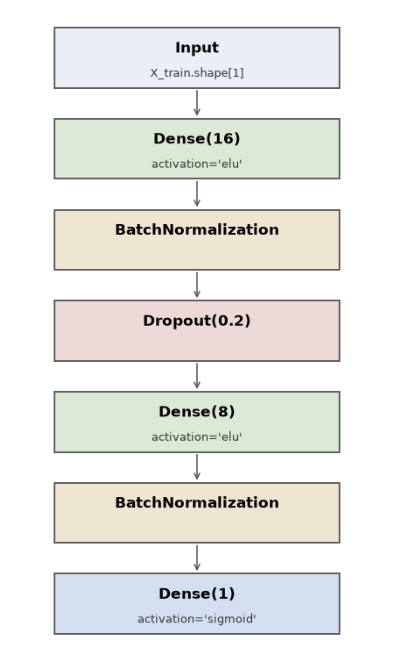

In [20]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

model = Sequential([
    Dense(16, input_dim=X_train.shape[1]),
    Activation('elu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(8),
    Activation('elu'),
    BatchNormalization(),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]
cb_list.append(ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=30, batch_size=32,
                    validation_data=(X_valid, y_valid_enc),
                    verbose=0,
                    callbacks=cb_list)

print(model.count_params())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


577


In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
577

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

각 은닉 Dense 층 바로 뒤에 활성화 함수 층을 하나씩 추가하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Activation`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

model = Sequential([
    Dense(16, input_dim=X_train.shape[1]),
    Activation('elu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(8),
    Activation('elu'),
    BatchNormalization(),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]
cb_list.append(ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=30, batch_size=32,
                    validation_data=(X_valid, y_valid_enc),
                    verbose=0,
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Accuracy와(과) 검증 Accuracy의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 13번 `history`
- 학습 Accuracy 과 검증 Accuracy 를 한 그래프(1개)에 함께 그리세요
- 그래프의 타이틀은 'Model Accuracy' 로, X축 이름은 'Epochs', Y축 이름은 'Accuracy' 로 표시하세요
- legend 에는 'train', 'val' 를 쓰세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

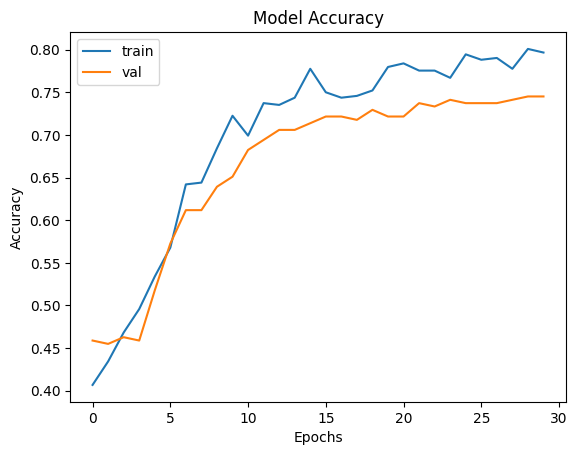

In [21]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답14_1 = 'title'
정답14_2 = 'legend'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 그래프 제목을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 5글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.tit__('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.leg___(['train', 'val'])
plt.show()

정답14_1 = 'tit__'   # 빈칸 1에 넣은 단어
정답14_2 = 'leg___'   # 빈칸 2에 넣은 단어
```

</details>